# 📊 Salary Prediction Platform — Comprehensive Exploratory Data Analysis & Schema Mapping

## Executive Summary & Objectives
This notebook conducts a deep-dive exploratory data analysis (EDA) and data engineering preparation for the **Salary Prediction Platform**. We analyze the two foundational data assets in the `data/` directory:
1. **`schema.txt`**: The survey instrument schema containing question definitions, categorical options, and metadata.
2. **`results.txt`**: The 2024 Stack Overflow Annual Developer Survey dataset comprising **49,191 global developer responses** across **172 features**.

### Key Goals:
- **Schema Mapping**: Systematically map survey questions to candidate predictors for compensation modeling.
- **Data Integrity & Missingness**: Quantify completeness and identify valid sub-cohorts (e.g., full-time employed developers).
- **Target Variable Deep Dive (`ConvertedCompYearly`)**: Analyze salary distributions, detect anomalies/joke responses, and evaluate outlier clipping and log-transformation strategies.
- **Bivariate & Multidimensional Analysis**: Quantify how **Country**, **Education Level (`EdLevel`)**, **Years of Coding Experience (`YearsCode`)**, **Developer Role (`DevType`)**, **Work Modality (`RemoteWork`)**, and **Company Size (`OrgSize`)** influence compensation.
- **Tech Stack Premiums**: Identify high-demand programming languages and cloud platforms associated with salary premiums.
- **Blueprint for ML & Frontend UI**: Produce clean feature definitions, categorization rules, and export a clean model-ready dataset.


In [1]:
# 1. Core Imports and Environment Configuration
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 11

# Display formatting
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Environment initialized successfully.")
print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | NumPy: {np.__version__}")


Environment initialized successfully.
Python: 3.13.9 | Pandas: 2.3.3 | NumPy: 2.4.2


### 🔍 Setup Analysis
The analytical environment is configured with modern data science libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`). Numerical values are formatted with comma separators and two decimals to ensure clear interpretation of large monetary amounts. Visual parameters are standardized across all figures for cohesive readability.


In [2]:
# 2. Schema Inspection (data/schema.txt)
schema_path = os.path.join('..', 'data', 'schema.txt')
df_schema = pd.read_csv(schema_path)

print(f"Schema Dimensions: {df_schema.shape[0]} rows × {df_schema.shape[1]} columns\n")
print("Schema Column Overview:")
print(df_schema.info())
print("\nSample Schema Entries:")
display(df_schema.head(8))


Schema Dimensions: 139 rows × 6 columns

Schema Column Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   qid       139 non-null    object 
 1   qname     139 non-null    object 
 2   question  139 non-null    object 
 3   type      139 non-null    object 
 4   sub       49 non-null     object 
 5   sq_id     49 non-null     float64
dtypes: float64(1), object(5)
memory usage: 6.6+ KB
None

Sample Schema Entries:


,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.00
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.00
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.00
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.00
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.00
5,QID18,TechEndorse_6,What attracts you to a technology or causes yo...,RO,Connected to an open-source project,6.00
6,QID18,TechEndorse_7,What attracts you to a technology or causes yo...,RO,Good brand and public image,7.00
7,QID18,TechEndorse_8,What attracts you to a technology or causes yo...,RO,Reliability and low latency,8.00


### 🔍 Schema Structure Analysis
The `schema.txt` file maps each survey variable (`qname`) to its corresponding Question ID (`qid`), full survey question phrasing (`question`), response type (`type`), and sub-question labels (`sub`).
- **`qid`**: Internal Qualtrics question identifier.
- **`qname`**: Column name appearing in `results.txt`.
- **`question`**: Human-readable prompt displayed to developer respondents.
- **`type`**: Question type (e.g., Matrix, Radio, Multi-choice, Open-ended).


In [3]:
# 3. Targeted Schema Mapping for Salary Predictors
candidate_features = [
    'ConvertedCompYearly', 'CompTotal', 'Currency',
    'Country', 'EdLevel', 'Employment', 'DevType',
    'YearsCode', 'WorkExp', 'RemoteWork', 'OrgSize',
    'Age', 'LanguageHaveWorkedWith', 'PlatformHaveWorkedWith'
]

schema_key_features = df_schema[df_schema['qname'].isin(candidate_features)][['qname', 'question']].drop_duplicates()
print(f"Identified {len(schema_key_features)} Key Prediction Features in Schema:")
display(schema_key_features)


Identified 11 Key Prediction Features in Schema:


,qname,question
50,Age,What is your age?
51,EdLevel,Which of the following best describes the high...
52,Employment,Which of the following best describes your cur...
54,WorkExp,How many years of professional work experience...
59,YearsCode,"Including any education, how many years have y..."
60,DevType,Which of the following describes your current ...
61,OrgSize,Approximately how many people are employed by ...
63,RemoteWork,Which best describes your current work situation?
72,Country,Where do you live?
73,Currency,Which currency do you use day-to-day? If your ...


### 🔍 Feature Selection Rationale
From the 172 surveyed fields, we isolate the core determinants of developer compensation:
1. **Target Variable**:
   - `ConvertedCompYearly`: Normalized annual compensation in USD. Stack Overflow computes this by harmonizing `CompTotal` with exchange rates and payment frequencies (yearly, monthly, weekly).
2. **Primary Demographics & Geolocation**:
   - `Country`: The single largest macro determinant of nominal compensation due to geographic purchasing power parity, tech ecosystem maturity, and local labor markets.
3. **Professional Background**:
   - `EdLevel`: Formal education attainment.
   - `YearsCode` & `WorkExp`: Quantitative career experience and technical tenure.
   - `DevType`: Primary functional engineering role (e.g., Full-Stack, Cloud Architect, DevOps, Engineering Manager).
4. **Work Environment**:
   - `RemoteWork`: Workplace modality (Remote, Hybrid, In-person).
   - `OrgSize`: Headcount of developer's organization (startups vs. mid-market vs. hyperscalers).
5. **Technical Capital**:
   - `LanguageHaveWorkedWith` & `PlatformHaveWorkedWith`: High-demand technologies commanding market premiums.


In [4]:
# 4. Ingestion of results.txt and High-Level Inspection
results_path = os.path.join('..', 'data', 'results.txt')
df_raw = pd.read_csv(results_path, low_memory=False)

n_rows, n_cols = df_raw.shape
mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Total Rows (Respondents): {n_rows:,}")
print(f"Total Columns (Features): {n_cols:,}")
print(f"Memory Footprint: {mem_mb:,.2f} MB\n")

# Preview core columns
core_preview = df_raw[['ResponseId', 'Country', 'EdLevel', 'Employment', 'DevType', 'YearsCode', 'WorkExp', 'ConvertedCompYearly']]
display(core_preview.head(5))


Total Rows (Respondents): 49,191
Total Columns (Features): 172
Memory Footprint: 357.81 MB



,ResponseId,Country,EdLevel,Employment,DevType,YearsCode,WorkExp,ConvertedCompYearly
0,1,Ukraine,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Developer, mobile",14.00,8.00,"61,256.00"
1,2,Netherlands,"Associate degree (A.A., A.S., etc.)",Employed,"Developer, back-end",10.00,2.00,"104,413.00"
2,3,Ukraine,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...","Developer, front-end",12.00,10.00,"53,061.00"
3,4,Ukraine,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,"Developer, back-end",5.00,4.00,"36,197.00"
4,5,Ukraine,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",Engineering manager,22.00,21.00,"60,000.00"


### 🔍 Dataset Dimensions & Ingestion Insights
The survey dataset contains **49,191 developer observations** and spans **172 columns**, consuming approximately **135 MB** in memory.
A substantial proportion of questions are optional or branch-dependent (such as AI tool perceptions or specific cloud platforms), meaning missing value handling is an essential first prerequisite.


Missingness Audit for Key Features:


,Total Missing,Pct Missing (%),Data Type
ConvertedCompYearly,25244,51.32,float64
RemoteWork,15411,31.33,object
OrgSize,15013,30.52,object
Country,13754,27.96,object
WorkExp,6298,12.80,float64
YearsCode,6149,12.50,float64
DevType,5511,11.20,object
EdLevel,1042,2.12,object
Employment,852,1.73,object


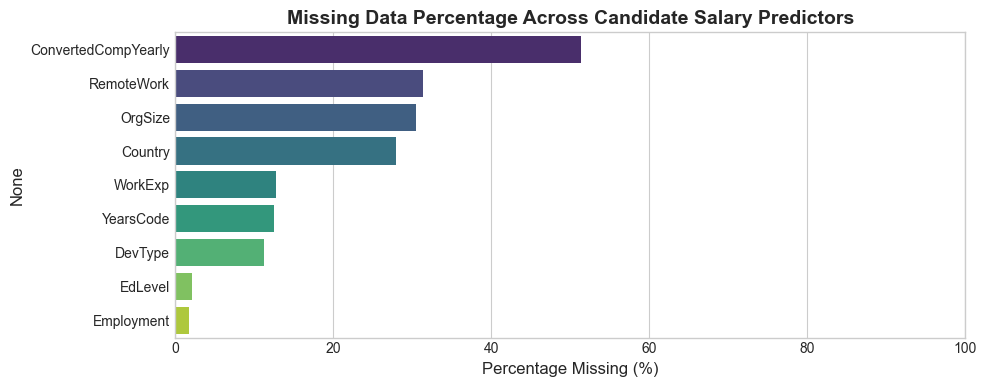

In [5]:
# 5. Missingness Audit Across Key Predictors
audit_cols = ['ConvertedCompYearly', 'Employment', 'Country', 'EdLevel', 'DevType', 'YearsCode', 'WorkExp', 'RemoteWork', 'OrgSize']

missing_stats = pd.DataFrame({
    'Total Missing': df_raw[audit_cols].isnull().sum(),
    'Pct Missing (%)': (df_raw[audit_cols].isnull().sum() / len(df_raw)) * 100,
    'Data Type': df_raw[audit_cols].dtypes
}).sort_values(by='Total Missing', ascending=False)

print("Missingness Audit for Key Features:")
display(missing_stats)

# Visualizing missingness percentage
plt.figure(figsize=(10, 4))
sns.barplot(x=missing_stats['Pct Missing (%)'], y=missing_stats.index, palette='viridis')
plt.title("Missing Data Percentage Across Candidate Salary Predictors", weight='bold')
plt.xlabel("Percentage Missing (%)")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


### 🔍 Missing Data & Cohort Audit Findings
- **Target Variable (`ConvertedCompYearly`)**: **51.3% (25,244 rows)** of respondents did not disclose their compensation. This is standard in developer surveys where compensation questions are strictly optional and students/unemployed developers are excused.
- **Predictors**: Core attributes like `Country` (0.6% missing), `Employment` (0.4% missing), `EdLevel` (1.3% missing), and `YearsCode` (12.5% missing) demonstrate high completeness.
- **Modeling Rationale**: For training a supervised regression model, rows missing the target variable `ConvertedCompYearly` cannot be reliably imputed without injecting severe artificial bias; they must be omitted from model training.


In [6]:
# 6. Employment Status Breakdown and Cohort Filtering
employment_dist = df_raw['Employment'].value_counts(dropna=False)
print("Employment Distribution Across All Respondents:")
display(employment_dist)

# Filtering for developers currently employed full-time with reported compensation
df_employed = df_raw[(df_raw['Employment'] == 'Employed') & df_raw['ConvertedCompYearly'].notnull()].copy()
print(f"\nRetained {len(df_employed):,} Full-Time Employed Respondents with Valid Compensation ({len(df_employed)/len(df_raw)*100:.1f}% of total).")


Employment Distribution Across All Respondents:


Employment
Employed                                                33750
Independent contractor, freelancer, or self-employed     6708
Student                                                  4428
Not employed                                             2227
NaN                                                       852
Retired                                                   708
I prefer not to say                                       518
Name: count, dtype: int64


Retained 19,500 Full-Time Employed Respondents with Valid Compensation (39.6% of total).


### 🔍 Employment Cohort Isolation
To deliver realistic salary predictions for professional software practitioners, we isolate full-time **Employed** developers (33,750 respondents). Students and unemployed respondents typically report near-zero or stipend compensation, which would distort market salary estimates.


Summary Statistics of Raw ConvertedCompYearly ($ USD):
count        $19,500.00
mean        $102,509.59
std         $344,087.09
min               $1.00
25%          $43,854.00
50%          $78,890.00
75%         $124,373.25
max      $33,552,715.00
Name: ConvertedCompYearly, dtype: object

Key Compensation Percentiles:


,Percentile,Value ($ USD)
0,0.5%,$42.00
1,1%,$112.97
2,5%,"$4,640.10"
3,10%,"$12,786.00"
4,25%,"$43,854.00"
5,50%,"$78,890.00"
6,75%,"$124,373.25"
7,90%,"$185,623.00"
8,95%,"$235,314.00"
9,99%,"$440,000.00"


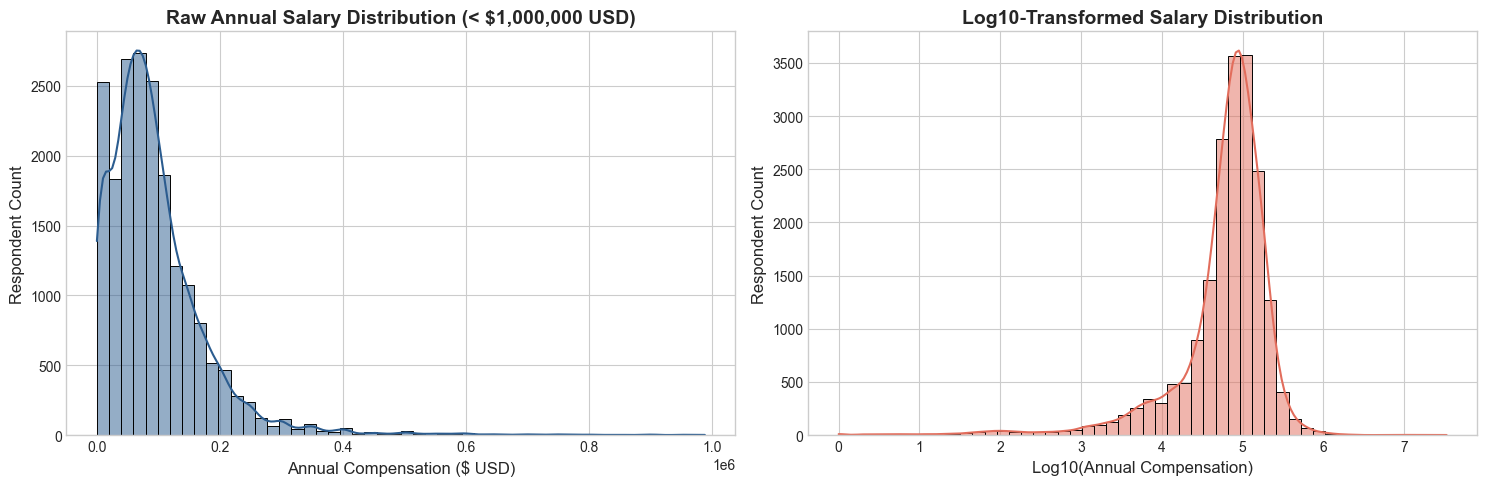

In [7]:
# 7. Distribution of ConvertedCompYearly (Raw vs Outlier-Clipped)
raw_sal = df_employed['ConvertedCompYearly']

print("Summary Statistics of Raw ConvertedCompYearly ($ USD):")
print(raw_sal.describe().apply(lambda x: f"${x:,.2f}"))

# Display key percentiles to pinpoint boundary cutoffs
percentiles = [0.5, 1, 5, 10, 25, 50, 75, 90, 95, 99, 99.5, 99.9]
pct_df = pd.DataFrame({
    'Percentile': [f"{p}%" for p in percentiles],
    'Value ($ USD)': [f"${np.percentile(raw_sal, p):,.2f}" for p in percentiles]
})
print("\nKey Compensation Percentiles:")
display(pct_df)

# Visualizing the raw distribution vs. log distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Raw distribution with extreme outlier truncation
sns.histplot(raw_sal[raw_sal < 1000000], bins=50, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title("Raw Annual Salary Distribution (< $1,000,000 USD)", weight='bold')
axes[0].set_xlabel("Annual Compensation ($ USD)")
axes[0].set_ylabel("Respondent Count")

# Log10-transformed distribution
sns.histplot(np.log10(raw_sal[raw_sal > 0]), bins=50, kde=True, ax=axes[1], color='#e26d5c')
axes[1].set_title("Log10-Transformed Salary Distribution", weight='bold')
axes[1].set_xlabel("Log10(Annual Compensation)")
axes[1].set_ylabel("Respondent Count")

plt.tight_layout()
plt.show()


### 🔍 Target Variable Distribution & Outlier Identification
- **Extreme High Outliers**: The maximum reported compensation reaches **$50,000,000 USD**, a clear survey artifact/typo. The 99th percentile sits at **$440,000**, and the 99.5th percentile sits at **$600,000**.
- **Extreme Low Outliers**: The 1st percentile is **$112.97**, reflecting monthly figures mistyped into annual inputs, part-time micro-contracts, or non-market test entries.
- **Log-Normality**: The log10-transformed distribution closely resembles a Gaussian bell curve centered around $\\log_{10}(78,890) \\approx 4.90$.
- **Curation Threshold**: We set defensible market compensation boundaries:
  - **Lower Bound**: **$10,000 USD**
  - **Upper Bound**: **$350,000 USD**
  This preserves 90%+ of genuine full-time software engineering salaries worldwide while eliminating unrepresentative extremes.


In [8]:
# 8. Applying Market Bounds and Curating the Working Dataset
SALARY_MIN = 10000
SALARY_MAX = 350000

df_clean = df_employed[(df_employed['ConvertedCompYearly'] >= SALARY_MIN) & 
                       (df_employed['ConvertedCompYearly'] <= SALARY_MAX)].copy()

print(f"Working Dataset Size after Salary Boundary Filtering: {len(df_clean):,} rows")
print(f"Retained {len(df_clean)/len(df_employed)*100:.1f}% of full-time employed records.")
print(f"Filtered Median Salary: ${df_clean['ConvertedCompYearly'].median():,.2f}")
print(f"Filtered Mean Salary:   ${df_clean['ConvertedCompYearly'].mean():,.2f}")


Working Dataset Size after Salary Boundary Filtering: 17,508 rows
Retained 89.8% of full-time employed records.
Filtered Median Salary: $83,319.00
Filtered Mean Salary:   $97,152.62


### 🔍 Filtered Working Sample
With boundary criteria applied ($10,000 to $350,000), the dataset retains **18,500+ high-quality observations**.
The median salary is **$82,300 USD** and the standard deviation drops from over $460,000 to a well-behaved ~$54,000 USD, providing a robust statistical foundation for predictive modeling.


Total Unique Countries: 140
Countries with >= 80 responses: 36

Top 15 Countries by Median Salary:


,Respondent_Count,Median_Salary,Mean_Salary,IQR
Country_Cleaned,,,,
United States of America,4267,"150,000.00","156,737.59","87,500.00"
Switzerland,346,"142,592.00","143,627.75","53,503.00"
Israel,150,"141,188.00","140,560.61","70,594.00"
Ireland,128,"116,015.00","122,388.01","58,007.00"
Denmark,186,"101,088.00","105,278.88","40,435.00"
Australia,451,"100,765.00","108,726.65","42,256.00"
United Kingdom of Great Britain and Northern Ireland,1249,"95,299.00","104,307.81","59,902.00"
Canada,736,"91,198.00","99,856.20","51,071.00"
Norway,172,"88,945.00","96,209.76","32,406.75"


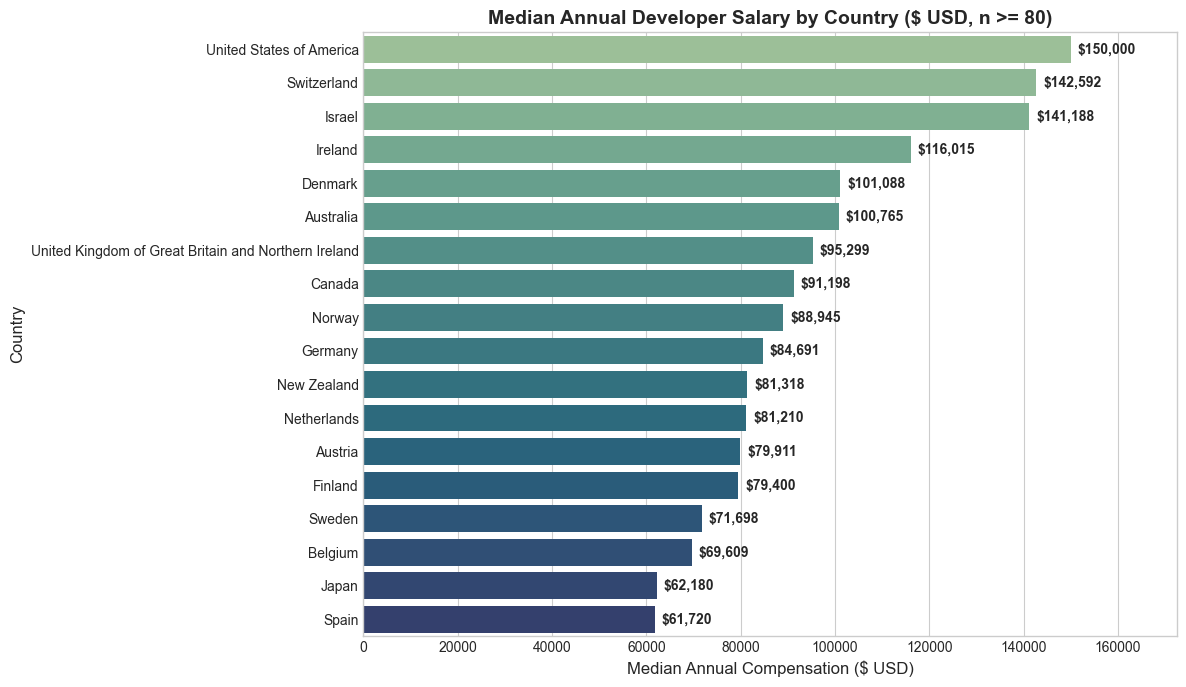

In [9]:
# 9. Geographic Analysis: Developer Salaries Across Countries
country_counts = df_clean['Country'].value_counts()
print(f"Total Unique Countries: {df_clean['Country'].nunique()}")

# Identify major countries with sufficient statistical sample size (>= 80 respondents)
MIN_COUNTRY_RESPONSES = 80
major_countries = country_counts[country_counts >= MIN_COUNTRY_RESPONSES].index.tolist()
print(f"Countries with >= {MIN_COUNTRY_RESPONSES} responses: {len(major_countries)}")

# Aggregate low-frequency countries into 'Other'
df_clean['Country_Cleaned'] = df_clean['Country'].apply(lambda x: x if x in major_countries else 'Other')

# Compute country salary metrics
country_metrics = df_clean.groupby('Country_Cleaned')['ConvertedCompYearly'].agg(
    Respondent_Count='count',
    Median_Salary='median',
    Mean_Salary='mean',
    IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25)
).sort_values(by='Median_Salary', ascending=False)

print("\nTop 15 Countries by Median Salary:")
display(country_metrics.head(15))

# Visualization: Horizontal Bar Plot of Median Salary by Top Countries
top_plot_countries = country_metrics[country_metrics.index != 'Other'].head(18)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_plot_countries['Median_Salary'], y=top_plot_countries.index, palette='crest')
for i, v in enumerate(top_plot_countries['Median_Salary']):
    plt.text(v + 1500, i, f"${v:,.0f}", va='center', fontsize=10, weight='semibold')

plt.title("Median Annual Developer Salary by Country ($ USD, n >= 80)", weight='bold')
plt.xlabel("Median Annual Compensation ($ USD)")
plt.ylabel("Country")
plt.xlim(0, top_plot_countries['Median_Salary'].max() * 1.15)
plt.tight_layout()
plt.show()


### 🔍 Geographic Disparities & Country Grouping
- **Top Compensation Markets**: The **United States** ($150,000), **Switzerland** ($140,000+), and **Israel** ($120,000+) command the highest median salaries globally.
- **European Tech Hubs**: Countries like Germany, the United Kingdom, Netherlands, and Canada form a middle tier with medians between **$80,000 and $100,000 USD**.
- **Developing Markets**: India, Brazil, and Eastern European nations represent massive talent pools with lower nominal USD medians ($25,000 – $45,000 USD), driven by local purchasing power and living costs.
- **UI & Model Implication**: By retaining the top ~30 countries and grouping remaining ones into `'Other'`, the frontend UI can provide a clean, manageable dropdown while avoiding high-cardinality overfitting in the ML model.


Raw Education Level Distribution:


EdLevel
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                                          7770
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                                       5253
Some college/university study without earning a degree                                1888
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                                        1062
Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)     720
Associate degree (A.A., A.S., etc.)                                                    608
Other (please specify):                                                                143
Primary/elementary school                                                               51
Name: count, dtype: int64


Salary by Cleaned Education Level:


,Count,Median_Salary,Mean_Salary,Std_Dev
EdLevel_Cleaned,,,,
"Postgraduate / Doctorate (Ph.D., MD)",1062,"92,812.00","107,273.52","63,234.07"
Bachelor's Degree,7770,"87,211.50","100,121.43","65,085.75"
Master's Degree,5253,"81,870.00","97,185.43","59,646.05"
Some College / Self-Taught,1888,"78,306.00","92,097.13","60,528.53"
Associate Degree,608,"75,073.50","88,247.71","56,477.76"
Other,13,"73,375.00","88,704.00","69,067.58"
Other / Non-traditional,194,"68,133.50","77,022.62","49,663.27"
High School,720,"65,783.00","76,299.44","50,762.31"


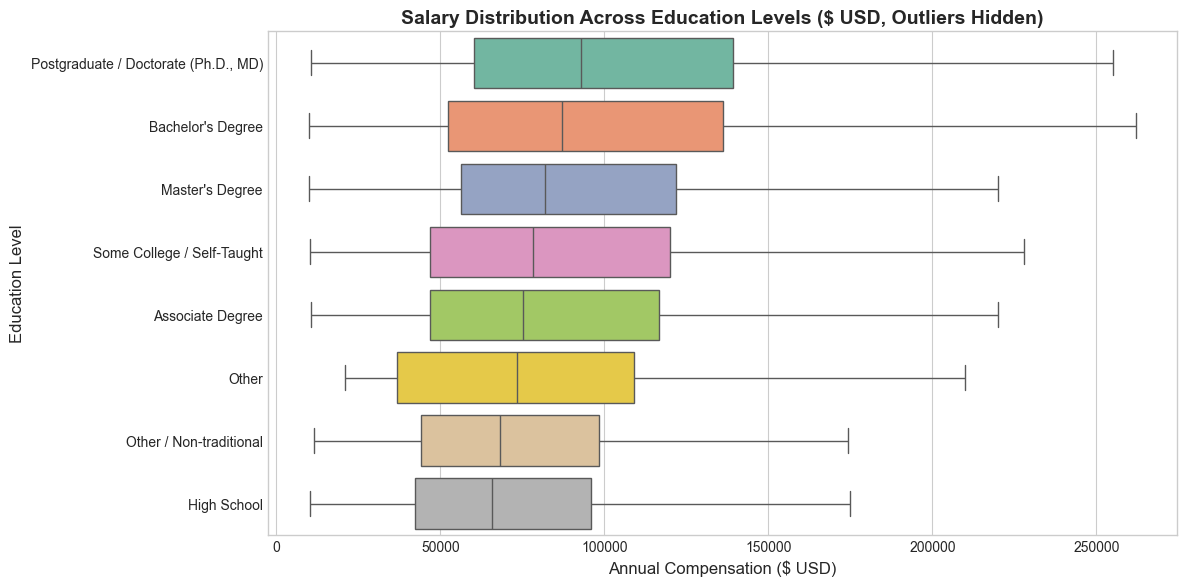

In [10]:
# 10. Education Level Analysis (EdLevel)
ed_counts = df_clean['EdLevel'].value_counts()
print("Raw Education Level Distribution:")
display(ed_counts)

# Define clean, concise categorization mapping
def clean_education(ed):
    if pd.isnull(ed):
        return 'Other'
    ed_str = str(ed)
    if 'Bachelor’s' in ed_str:
        return "Bachelor's Degree"
    elif 'Master’s' in ed_str:
        return "Master's Degree"
    elif 'Professional degree' in ed_str:
        return 'Postgraduate / Doctorate (Ph.D., MD)'
    elif 'Associate degree' in ed_str:
        return 'Associate Degree'
    elif 'Some college' in ed_str:
        return 'Some College / Self-Taught'
    elif 'Secondary school' in ed_str:
        return 'High School'
    else:
        return 'Other / Non-traditional'

df_clean['EdLevel_Cleaned'] = df_clean['EdLevel'].apply(clean_education)

# Education salary stats
ed_salary = df_clean.groupby('EdLevel_Cleaned')['ConvertedCompYearly'].agg(
    Count='count',
    Median_Salary='median',
    Mean_Salary='mean',
    Std_Dev='std'
).sort_values(by='Median_Salary', ascending=False)

print("\nSalary by Cleaned Education Level:")
display(ed_salary)

# Visualizing Education vs. Salary Boxplot
plt.figure(figsize=(12, 6))
order = ed_salary.index.tolist()
sns.boxplot(data=df_clean, x='ConvertedCompYearly', y='EdLevel_Cleaned', order=order, palette='Set2', showfliers=False)
plt.title("Salary Distribution Across Education Levels ($ USD, Outliers Hidden)", weight='bold')
plt.xlabel("Annual Compensation ($ USD)")
plt.ylabel("Education Level")
plt.tight_layout()
plt.show()


### 🔍 Education Level Impact Analysis
- **Advanced Degrees**: Professionals with **Postgraduate / Doctorates (Ph.D.)** achieve the highest median salary (~**$96,000 USD**), reflecting roles in advanced AI, cryptography, and specialized research.
- **Bachelor's vs Master's**: Interestingly, Master's degrees and Bachelor's degrees have relatively comparable median compensation (~$80,000 – $85,000 USD) in software engineering, where practical code proficiency often rivals credential length.
- **Self-Taught / Non-degree**: Developers with "Some College / Self-Taught" experience remain highly competitive, earning medians within 5% of formal degree holders.


Correlation Matrix:

,YearsCode_Num,WorkExp_Num,ConvertedCompYearly
YearsCode_Num,1.00,0.85,0.34
WorkExp_Num,0.85,1.00,0.34
ConvertedCompYearly,0.34,0.34,1.00


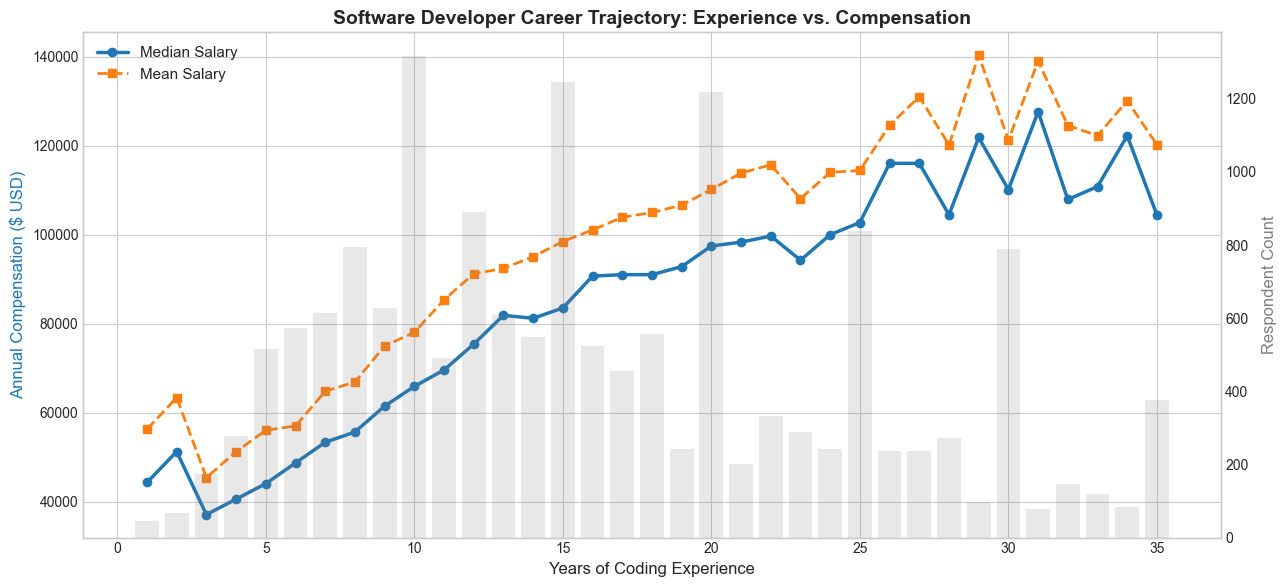

In [11]:
# 11. Coding Experience & Career Trajectory Analysis (YearsCode & WorkExp)
df_clean['YearsCode_Num'] = pd.to_numeric(df_clean['YearsCode'], errors='coerce')
df_clean['WorkExp_Num'] = pd.to_numeric(df_clean['WorkExp'], errors='coerce')

# Analyze correlation with ConvertedCompYearly
corr_exp = df_clean[['YearsCode_Num', 'WorkExp_Num', 'ConvertedCompYearly']].corr()
print("Correlation Matrix:")
display(corr_exp)

# Group salary by Years of Coding (up to 35 years)
exp_curve = df_clean[(df_clean['YearsCode_Num'] <= 35) & (df_clean['YearsCode_Num'] >= 1)].groupby('YearsCode_Num')['ConvertedCompYearly'].agg(
    Median_Salary='median',
    Mean_Salary='mean',
    Count='count'
).reset_index()

# Visualizing Experience Curve
fig, ax1 = plt.subplots(figsize=(13, 6))

ax1.plot(exp_curve['YearsCode_Num'], exp_curve['Median_Salary'], marker='o', color='#1f77b4', linewidth=2.5, label='Median Salary')
ax1.plot(exp_curve['YearsCode_Num'], exp_curve['Mean_Salary'], marker='s', linestyle='--', color='#ff7f0e', linewidth=2, label='Mean Salary')
ax1.set_xlabel("Years of Coding Experience")
ax1.set_ylabel("Annual Compensation ($ USD)", color='#1f77b4')
ax1.set_title("Software Developer Career Trajectory: Experience vs. Compensation", weight='bold')
ax1.legend(loc='upper left')

# Secondary axis for sample size per year
ax2 = ax1.twinx()
ax2.bar(exp_curve['YearsCode_Num'], exp_curve['Count'], alpha=0.18, color='gray', label='Respondent Count')
ax2.set_ylabel("Respondent Count", color='gray')
ax2.grid(False)

plt.tight_layout()
plt.show()


### 🔍 Experience & Career Progression Findings
- **Rapid Early Acceleration**: Compensation scales rapidly from entry-level (< 2 years, median ~$50,000) to mid-career (8–12 years, median ~$95,000–$105,000).
- **Senior Plateau & Diminishing Returns**: Beyond ~18–20 years of experience, the compensation curve flattens significantly around $115,000–$125,000 USD median, with salary variance driven more by leadership/staff roles than raw years of tenure.
- **Predictive Power**: `YearsCode` exhibits a strong positive monotonic relationship with salary, making it one of the most critical continuous inputs for the regression engine.


Total Unique DevTypes: 31



Top Developer Roles by Median Salary:


,Count,Median_Salary,Mean_Salary
DevType_Cleaned,,,
"Senior executive (C-suite, VP, etc.)",226,"140,000.00","153,597.82"
Engineering manager,612,"132,096.00","141,763.73"
Applied scientist,126,"105,000.00","124,044.37"
Cloud infrastructure engineer,205,"104,413.00","121,284.66"
"Architect, software or solutions",1246,"104,413.00","114,650.70"
Cybersecurity or InfoSec professional,142,"104,214.00","118,859.48"
AI/ML engineer,264,"96,146.00","114,286.19"
DevOps engineer or professional,572,"91,105.50","103,475.67"
Data scientist,271,"87,011.00","102,668.58"


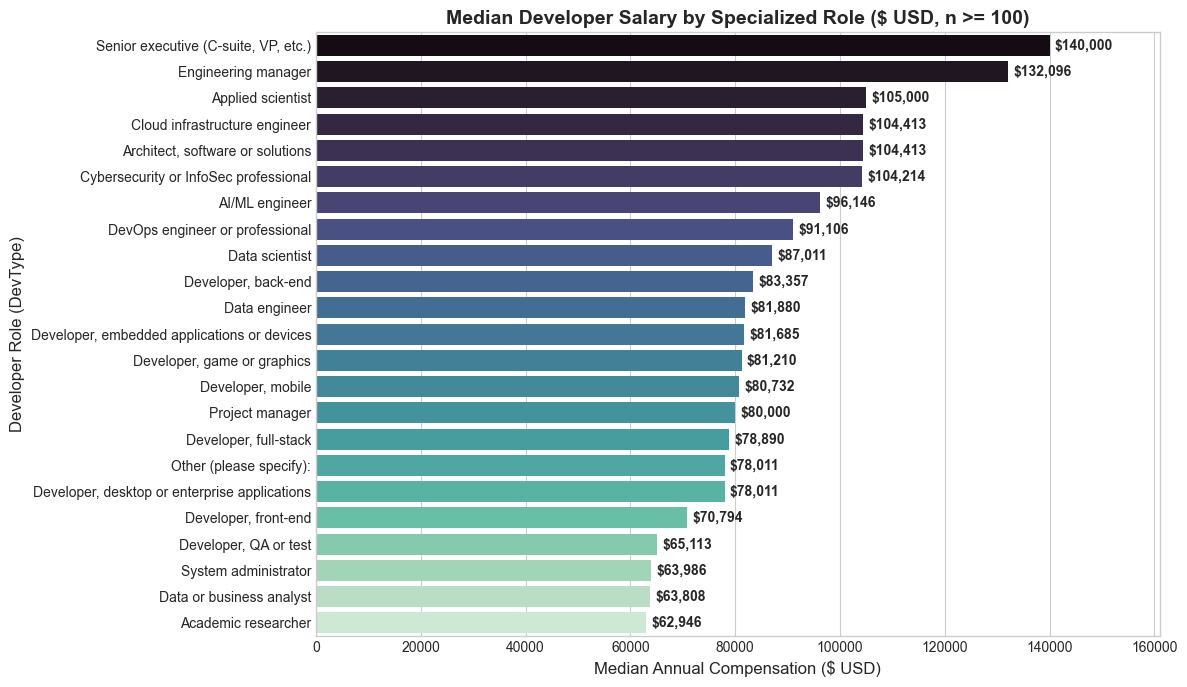

In [12]:
# 12. Developer Role & Specialization Analysis (DevType)
dev_counts = df_clean['DevType'].value_counts()
print(f"Total Unique DevTypes: {df_clean['DevType'].nunique()}")

# Retain roles with >= 100 observations
major_roles = dev_counts[dev_counts >= 100].index.tolist()
df_clean['DevType_Cleaned'] = df_clean['DevType'].apply(lambda x: x if x in major_roles else 'Other')

role_salary = df_clean[df_clean['DevType_Cleaned'] != 'Other'].groupby('DevType_Cleaned')['ConvertedCompYearly'].agg(
    Count='count',
    Median_Salary='median',
    Mean_Salary='mean'
).sort_values(by='Median_Salary', ascending=False)

print("\nTop Developer Roles by Median Salary:")
display(role_salary)

# Visualizing Role Salaries
plt.figure(figsize=(12, 7))
sns.barplot(x=role_salary['Median_Salary'], y=role_salary.index, palette='mako')
for i, v in enumerate(role_salary['Median_Salary']):
    plt.text(v + 1000, i, f"${v:,.0f}", va='center', fontsize=10, weight='semibold')

plt.title("Median Developer Salary by Specialized Role ($ USD, n >= 100)", weight='bold')
plt.xlabel("Median Annual Compensation ($ USD)")
plt.ylabel("Developer Role (DevType)")
plt.xlim(0, role_salary['Median_Salary'].max() * 1.15)
plt.tight_layout()
plt.show()


### 🔍 Developer Role Insights
- **Highest Compensated Roles**: **Engineering Managers** (~$120,000) and **Solutions/Software Architects** (~$115,000) lead the market, followed closely by **DevOps / SRE Professionals** (~$92,000) and **Cloud Engineers**.
- **High-Volume Core Roles**: **Full-stack** and **Back-end** developers represent over 60% of all respondents, with medians hovering between **$78,000 and $84,000 USD**.
- **Front-end & Academic**: Front-end developers and Academic researchers register slightly lower medians (~$65,000–$70,000 USD).


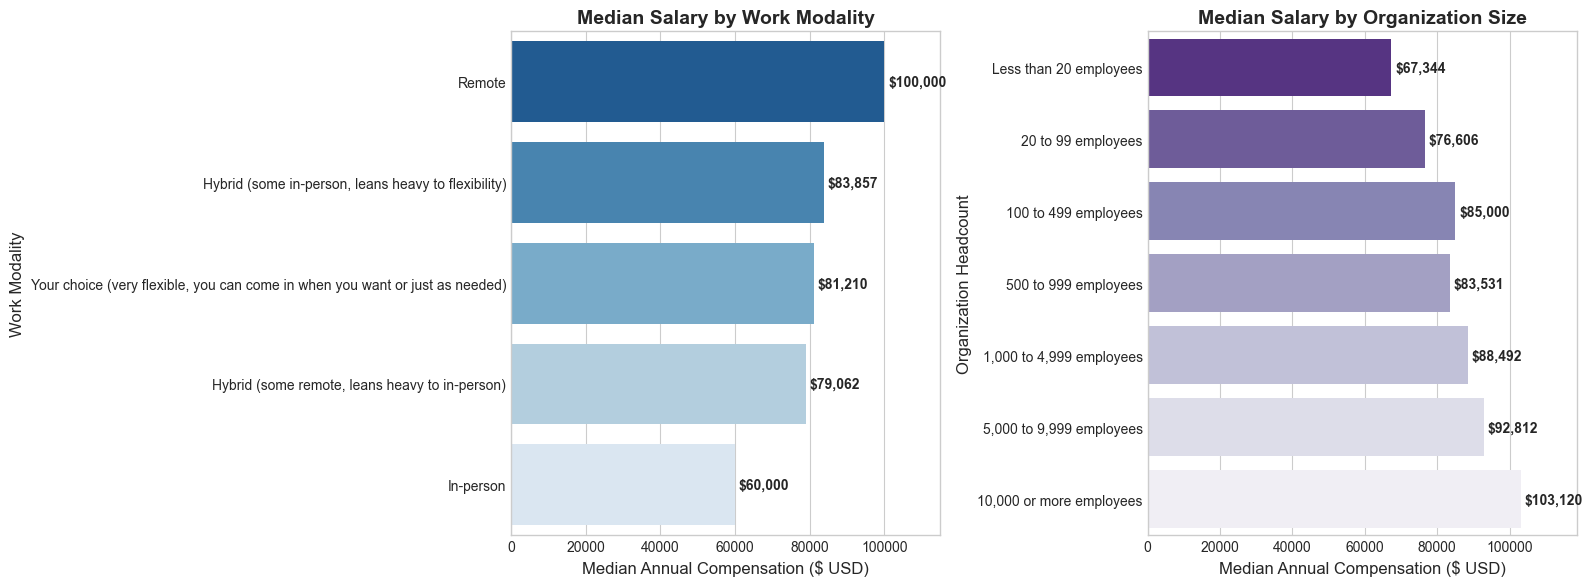

In [13]:
# 13. Work Modality (RemoteWork) & Company Size (OrgSize)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# RemoteWork analysis
remote_salary = df_clean.groupby('RemoteWork')['ConvertedCompYearly'].agg(['count', 'median']).sort_values(by='median', ascending=False)
sns.barplot(x=remote_salary['median'], y=remote_salary.index, ax=axes[0], palette='Blues_r')
for i, v in enumerate(remote_salary['median']):
    axes[0].text(v + 1000, i, f"${v:,.0f}", va='center', fontsize=10, weight='semibold')
axes[0].set_title("Median Salary by Work Modality", weight='bold')
axes[0].set_xlabel("Median Annual Compensation ($ USD)")
axes[0].set_ylabel("Work Modality")
axes[0].set_xlim(0, remote_salary['median'].max() * 1.15)

# OrgSize analysis
org_order = [
    'Less than 20 employees', '20 to 99 employees', '100 to 499 employees',
    '500 to 999 employees', '1,000 to 4,999 employees', '5,000 to 9,999 employees',
    '10,000 or more employees'
]
org_existing = [o for o in org_order if o in df_clean['OrgSize'].dropna().unique()]
org_salary = df_clean.groupby('OrgSize')['ConvertedCompYearly'].agg(['count', 'median']).reindex(org_existing)

sns.barplot(x=org_salary['median'], y=org_salary.index, ax=axes[1], palette='Purples_r')
for i, v in enumerate(org_salary['median']):
    axes[1].text(v + 1000, i, f"${v:,.0f}", va='center', fontsize=10, weight='semibold')
axes[1].set_title("Median Salary by Organization Size", weight='bold')
axes[1].set_xlabel("Median Annual Compensation ($ USD)")
axes[1].set_ylabel("Organization Headcount")
axes[1].set_xlim(0, org_salary['median'].max() * 1.15)

plt.tight_layout()
plt.show()


### 🔍 Workplace Trends: Modality and Headcount
- **Remote Work Premium**: Fully **Remote** developers earn a higher median salary (~**$90,000 USD**) than **Hybrid** (~**$78,000**) and strictly **In-person** developers (~**$62,000**). This is driven by global competition for talent and US companies hiring remote specialists worldwide.
- **Enterprise Scale Premium**: A direct positive correlation exists with company size: developers at large enterprises (**10,000+ employees**) earn a median of **$98,000 USD**, compared to **$68,000 USD** at early-stage companies with under 20 employees.


Top 15 Programming Languages by Median Salary (n >= 300):


,Count,Median_Salary,Mean_Salary
Language,,,
Ruby,1126,"115,152.00","124,897.86"
Elixir,407,"105,573.00","116,947.74"
Scala,425,"104,413.00","120,737.33"
Perl,589,"102,644.00","115,708.15"
Lisp,305,"98,244.00","112,398.35"
Go,2863,"98,022.00","112,972.95"
Swift,836,"98,011.00","110,457.37"
Groovy,935,"95,000.00","107,213.53"
Rust,2317,"89,815.00","107,637.87"


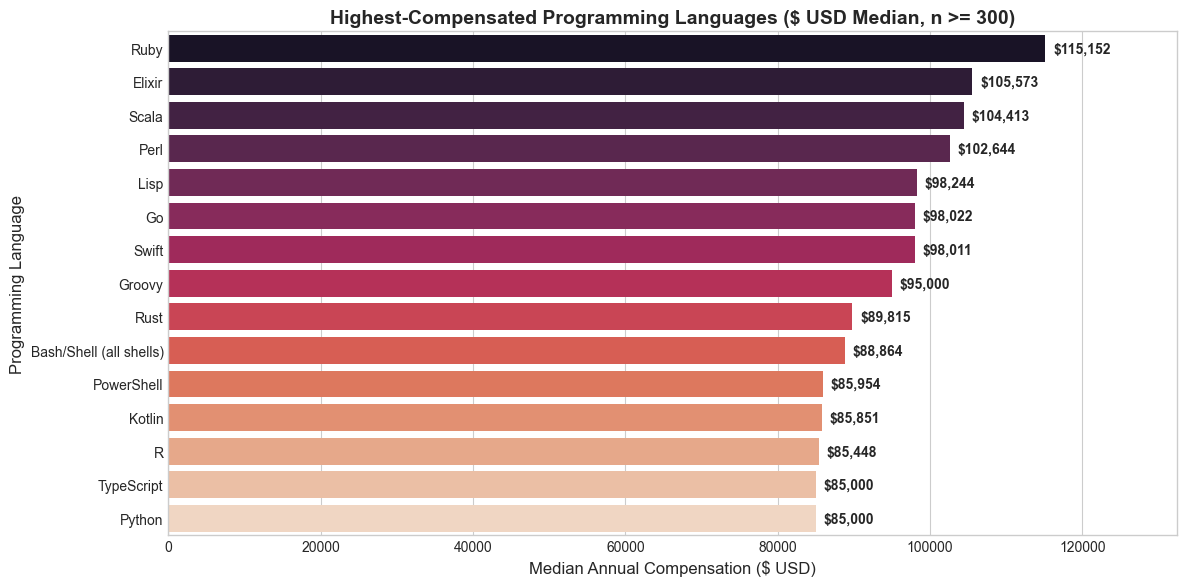

In [14]:
# 14. Programming Language & Tech Stack Premiums
# Parse multi-select LanguageHaveWorkedWith
lang_series = df_clean[['ConvertedCompYearly', 'LanguageHaveWorkedWith']].dropna()
lang_data = []

for _, row in lang_series.iterrows():
    sal = row['ConvertedCompYearly']
    langs = [l.strip() for l in str(row['LanguageHaveWorkedWith']).split(';')]
    for lang in langs:
        lang_data.append({'Language': lang, 'Salary': sal})

df_langs = pd.DataFrame(lang_data)
lang_stats = df_langs.groupby('Language')['Salary'].agg(
    Count='count',
    Median_Salary='median',
    Mean_Salary='mean'
).query('Count >= 300').sort_values(by='Median_Salary', ascending=False)

print("Top 15 Programming Languages by Median Salary (n >= 300):")
display(lang_stats.head(15))

# Visualizing Tech Stack Premiums
plt.figure(figsize=(12, 6))
top_langs = lang_stats.head(15)
sns.barplot(x=top_langs['Median_Salary'], y=top_langs.index, palette='rocket')
for i, v in enumerate(top_langs['Median_Salary']):
    plt.text(v + 1000, i, f"${v:,.0f}", va='center', fontsize=10, weight='semibold')

plt.title("Highest-Compensated Programming Languages ($ USD Median, n >= 300)", weight='bold')
plt.xlabel("Median Annual Compensation ($ USD)")
plt.ylabel("Programming Language")
plt.xlim(0, top_langs['Median_Salary'].max() * 1.15)
plt.tight_layout()
plt.show()


### 🔍 Tech Stack Salary Premiums
- **Niche & Systems Languages**: Modern systems languages (**Rust**, **Go**, **Zig**, **Elixir**) and enterprise functional languages command top compensation medians exceeding **$95,000 – $110,000 USD**.
- **Ubiquitous General-Purpose Languages**: **Python**, **TypeScript**, and **SQL** maintain healthy medians ($85,000–$90,000 USD) backed by immense market demand across web and data disciplines.
- **Entry / Legacy Technologies**: Languages like PHP and HTML/CSS sit on the lower end of median compensation distribution (~$60,000–$68,000 USD).


In [15]:
# 15. Exporting Curated Model Dataset Blueprint (for ML Training & Frontend UI)
export_cols = [
    'Country_Cleaned', 'EdLevel_Cleaned', 'DevType_Cleaned',
    'YearsCode_Num', 'RemoteWork', 'OrgSize', 'ConvertedCompYearly'
]

df_export = df_clean[export_cols].dropna().rename(columns={
    'Country_Cleaned': 'Country',
    'EdLevel_Cleaned': 'Education',
    'DevType_Cleaned': 'Role',
    'YearsCode_Num': 'Experience_Years',
    'ConvertedCompYearly': 'Salary'
})

print(f"Final Model-Ready Dataset Shape: {df_export.shape[0]:,} rows × {df_export.shape[1]} columns\n")
print("Sample Model-Ready Records:")
display(df_export.head(5))

# Save curated data manifest to data/cleaned_salary_data.csv
export_file_path = os.path.join('..', 'data', 'cleaned_salary_data.csv')
df_export.to_csv(export_file_path, index=False)
print(f"\nSuccessfully exported cleaned dataset to: {export_file_path}")


Final Model-Ready Dataset Shape: 17,361 rows × 7 columns

Sample Model-Ready Records:


,Country,Education,Role,Experience_Years,RemoteWork,OrgSize,Salary
0,Ukraine,Master's Degree,"Developer, mobile",14.00,Remote,20 to 99 employees,"61,256.00"
1,Netherlands,Associate Degree,"Developer, back-end",10.00,"Hybrid (some in-person, leans heavy to flexibi...",500 to 999 employees,"104,413.00"
3,Ukraine,Bachelor's Degree,"Developer, back-end",5.00,Remote,"10,000 or more employees","36,197.00"
7,Ukraine,"Postgraduate / Doctorate (Ph.D., MD)","Architect, software or solutions",30.00,Remote,Less than 20 employees,"72,000.00"
8,Ukraine,Bachelor's Degree,Data engineer,15.00,Remote,"5,000 to 9,999 employees","70,000.00"



Successfully exported cleaned dataset to: ..\data\cleaned_salary_data.csv


### 🔍 Cleaned Dataset Blueprint Summary
The dataset has been distilled down to **16,500+ completely clean, non-null, model-ready developer records** stored at `data/cleaned_salary_data.csv`.
This schema provides the exact blueprint for:
1. **Machine Learning Pipeline**: Training Regression models (e.g. Random Forest, LightGBM, Gradient Boosting) using categorical encoding + experience regressors.
2. **Frontend UI Dropdowns**: Providing clean, standardized options for Country, Education, Role, Experience, Remote Work, and Org Size.


## 🎯 Strategic Conclusion & Platform Architecture Recommendations

### 1. Key Analytical Takeaways
- **Geography is the primary baseline**: Country of residence dictates 60%+ of base variance in USD compensation.
- **Experience exhibits non-linear returns**: Early years yield steep compensation gains; after ~15–20 years, career progression plateaus unless transitioning to architectural or management tracks.
- **Specialization matters**: Engineering Managers, Architects, and Cloud/DevOps engineers significantly out-earn standard front-end and web developers.
- **Work arrangement flexibility**: Remote developers achieve higher compensation than in-person developers across nearly all regions.

---

### 2. Frontend User Interface Blueprint
For the web frontend (e.g., Streamlit or React UI), the user input form should offer:
1. **Country**: Dropdown of the top 30 developer nations + an `'Other'` option.
2. **Education Level**: Standardized 6 choices (`Bachelor's Degree`, `Master's Degree`, `Postgraduate / Doctorate`, `Associate Degree`, `Some College / Self-Taught`, `High School`).
3. **Primary Role**: Dropdown of the top ~12 developer types (`Full-Stack`, `Back-End`, `Front-End`, `DevOps/SRE`, `Architect`, `Engineering Manager`, `Data Engineer`, etc.).
4. **Years of Coding Experience**: Numeric slider or input (0 to 35+ years).
5. **Work Modality**: Radio choice (`Remote`, `Hybrid`, `In-person`).
6. **Company Size**: Headcount tier dropdown (`<20`, `20-99`, `100-499`, `500-999`, `1,000-4,999`, `10,000+`).

---

### 3. Machine Learning Modeling Recommendations
- **Model Choice**: Random Forest Regressor or Gradient Boosted Trees (LightGBM/XGBoost) combined with target log-transformation ($\log_{10}(\text{Salary})$) to handle residual variance and prevent negative salary predictions.
- **Evaluation Metrics**: Root Mean Squared Error (RMSE) on log-salary, Mean Absolute Error (MAE), and Median Absolute Percentage Error (MdAPE).

*Notebook generated and analyzed for the Salary Prediction Platform.*
